In [1]:



import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from statsmodels.stats.outliers_influence import variance_inflation_factor

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

housing = fetch_california_housing(as_frame=True)
df = housing.frame
df.head()


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [3]:

print("Dataset Shape:", df.shape)

print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])


Dataset Shape: (20640, 9)
Number of Rows: 20640
Number of Columns: 9


In [4]:

print("Dataset Information:")
df.info()


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [6]:
print("Missing Values:")
print(df.isnull().sum())
print("\nTotal Missing Values:", df.isnull().sum().sum())


Missing Values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Total Missing Values: 0


In [7]:
print("Total Duplicate Records:", df.duplicated().sum())


Total Duplicate Records: 0


In [8]:

df = df.drop_duplicates()

df = df.dropna()

print("Dataset Shape After Cleaning:", df.shape)

print("Remaining Missing Values:", df.isnull().sum().sum())
print("Remaining Duplicates:", df.duplicated().sum())


Dataset Shape After Cleaning: (20640, 9)
Remaining Missing Values: 0
Remaining Duplicates: 0


In [9]:



X = df.drop('MedHouseVal', axis=1)
y = df['MedHouseVal']

print("Input Features:")
print(X.columns.tolist())

print("\nTarget Variable:")
print(y.name)


Input Features:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']

Target Variable:
MedHouseVal


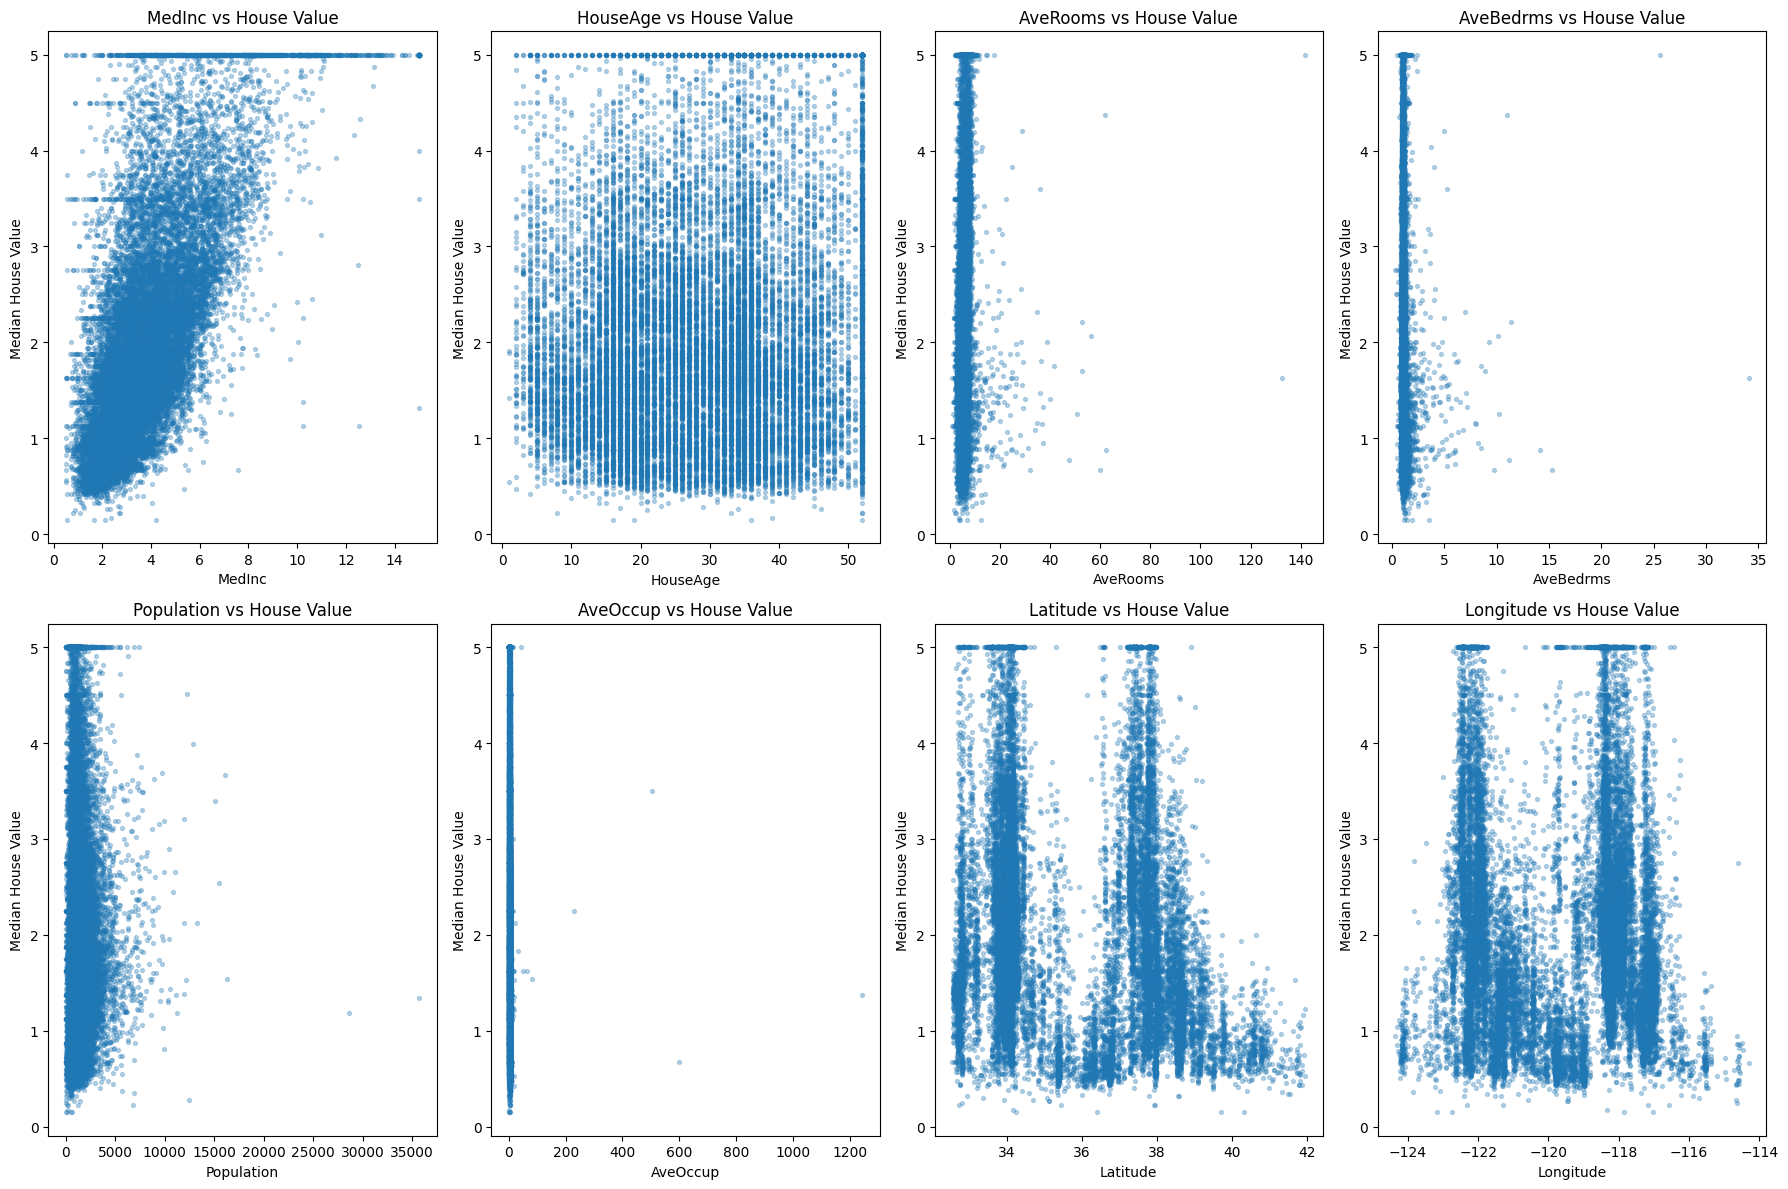

In [10]:



features = X.columns

plt.figure(figsize=(18, 12))

for i, feature in enumerate(features):
    plt.subplot(2, 4, i+1)
    plt.scatter(df[feature], y, alpha=0.3, s=8)
    plt.xlabel(feature)
    plt.ylabel('Median House Value')
    plt.title(f'{feature} vs House Value')

plt.tight_layout()
plt.show()


In [11]:


correlation_matrix = df.corr()

print("Correlation Matrix:")
print(correlation_matrix)


Correlation Matrix:
               MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  \
MedInc       1.000000 -0.119034  0.326895  -0.062040    0.004834  0.018766   
HouseAge    -0.119034  1.000000 -0.153277  -0.077747   -0.296244  0.013191   
AveRooms     0.326895 -0.153277  1.000000   0.847621   -0.072213 -0.004852   
AveBedrms   -0.062040 -0.077747  0.847621   1.000000   -0.066197 -0.006181   
Population   0.004834 -0.296244 -0.072213  -0.066197    1.000000  0.069863   
AveOccup     0.018766  0.013191 -0.004852  -0.006181    0.069863  1.000000   
Latitude    -0.079809  0.011173  0.106389   0.069721   -0.108785  0.002366   
Longitude   -0.015176 -0.108197 -0.027540   0.013344    0.099773  0.002476   
MedHouseVal  0.688075  0.105623  0.151948  -0.046701   -0.024650 -0.023737   

             Latitude  Longitude  MedHouseVal  
MedInc      -0.079809  -0.015176     0.688075  
HouseAge     0.011173  -0.108197     0.105623  
AveRooms     0.106389  -0.027540     0.151948  
AveBedr

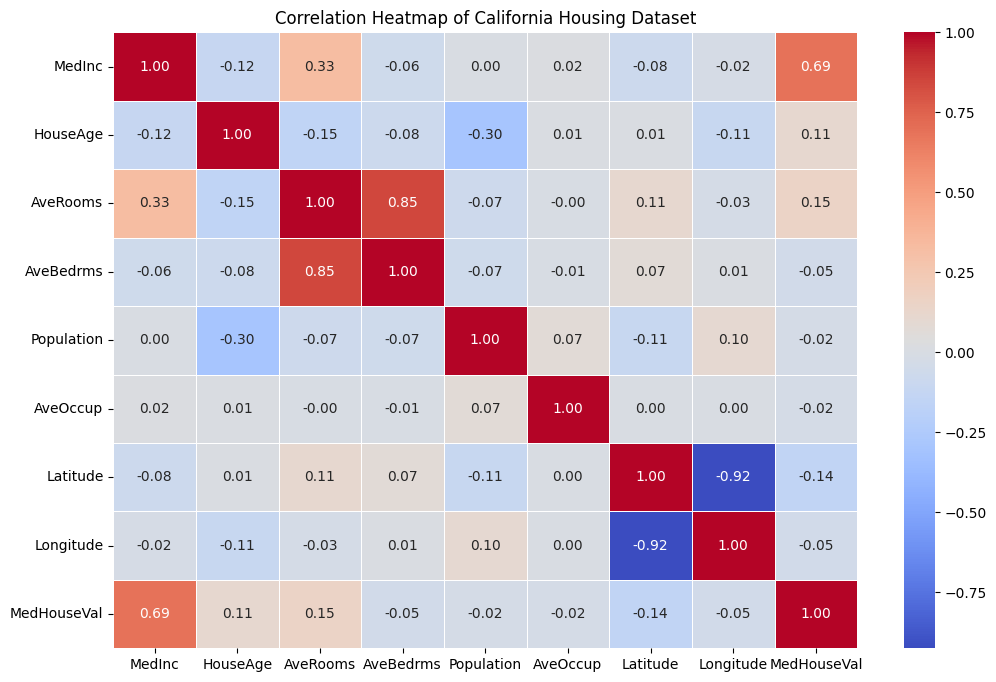

In [12]:

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of California Housing Dataset')
plt.show()


In [13]:

target_correlation = correlation_matrix['MedHouseVal']

print("Correlation with House Price:")
print(target_correlation.sort_values(ascending=False))


Correlation with House Price:
MedHouseVal    1.000000
MedInc         0.688075
AveRooms       0.151948
HouseAge       0.105623
AveOccup      -0.023737
Population    -0.024650
Longitude     -0.045967
AveBedrms     -0.046701
Latitude      -0.144160
Name: MedHouseVal, dtype: float64


### Data Visualization and Correlation Analysis

Scatter plots were created to study the relationship between all eight independent features and the target variable, MedHouseVal.

A correlation matrix and heatmap were generated to identify positive and negative relationships between the features.

The analysis indicates that Median Income (MedInc) has a relatively strong positive relationship with median house value. Other features show weaker or more complex relationships.

The correlation between input features was also examined to identify possible multicollinearity.

Correlation indicates association between variables and does not necessarily establish a cause-and-effect relationship.

In [14]:

sample_data = df[['MedInc', 'HouseAge', 'MedHouseVal']].head(6)

print(sample_data)


   MedInc  HouseAge  MedHouseVal
0  8.3252      41.0        4.526
1  8.3014      21.0        3.585
2  7.2574      52.0        3.521
3  5.6431      52.0        3.413
4  3.8462      52.0        3.422
5  4.0368      52.0        2.697


In [15]:

X_manual = np.column_stack((
    np.ones(6),
    sample_data['MedInc'].values,
    sample_data['HouseAge'].values
))

y_manual = sample_data['MedHouseVal'].values

print("Design Matrix X:")
print(X_manual)

print("\nTarget Vector Y:")
print(y_manual)


Design Matrix X:
[[ 1.      8.3252 41.    ]
 [ 1.      8.3014 21.    ]
 [ 1.      7.2574 52.    ]
 [ 1.      5.6431 52.    ]
 [ 1.      3.8462 52.    ]
 [ 1.      4.0368 52.    ]]

Target Vector Y:
[4.526 3.585 3.521 3.413 3.422 2.697]


In [16]:

X_transpose = X_manual.T

XTX = np.dot(X_transpose, X_manual)

print("X Transpose X:")
print(XTX)


X Transpose X:
[[6.00000000e+00 3.74101000e+01 2.70000000e+02]
 [3.74101000e+01 2.53825638e+02 1.59640460e+03]
 [2.70000000e+02 1.59640460e+03 1.29380000e+04]]


In [17]:

XTY = np.dot(X_transpose, y_manual)

print("X Transpose Y:")
print(XTY)


X Transpose Y:
[ 21.164     136.3025259 939.607    ]


In [18]:

B = np.linalg.solve(XTX, XTY)

print("Regression Coefficients:")
print("B0:", B[0])
print("B1:", B[1])
print("B2:", B[2])


Regression Coefficients:
B0: 1.2563591611656633
B1: 0.26774577638117103
B2: 0.01336832875558805


In [19]:

predicted_value = np.dot(X_manual[0], B)

actual_value = y_manual[0]

residual = actual_value - predicted_value

print("Actual Value:", actual_value)
print("Predicted Value:", predicted_value)
print("Residual:", residual)


Actual Value: 4.526
Predicted Value: 4.033497777673299
Residual: 0.49250222232670104


In [20]:

manual_model = LinearRegression()

manual_model.fit(
    sample_data[['MedInc', 'HouseAge']],
    sample_data['MedHouseVal']
)

print("Library Intercept:", manual_model.intercept_)

print("Library Coefficients:", manual_model.coef_)

print("Manual Coefficients:", B)


Library Intercept: 1.2563591611656566
Library Coefficients: [0.26774578 0.01336833]
Manual Coefficients: [1.25635916 0.26774578 0.01336833]


In [21]:

X = df.drop('MedHouseVal', axis=1)
y = df['MedHouseVal']


In [22]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)


Training Data: (16512, 8)
Testing Data: (4128, 8)
Training Target: (16512,)
Testing Target: (4128,)


In [23]:

train_correlation = pd.concat(
    [X_train, y_train], axis=1
).corr(numeric_only=True)['MedHouseVal'].drop('MedHouseVal')

best_feature = train_correlation.abs().idxmax()

print("Best Feature:", best_feature)
print("Correlation:", train_correlation[best_feature])


Best Feature: MedInc
Correlation: 0.6906466061467654


In [24]:

single_model = LinearRegression()

single_model.fit(
    X_train[[best_feature]],
    y_train
)

print("Intercept:", single_model.intercept_)
print("Coefficient:", single_model.coef_[0])


Intercept: 0.4445972916907879
Coefficient: 0.4193384939381271


In [25]:

single_predictions = single_model.predict(
    X_test[[best_feature]]
)

print("Actual Values:")
print(y_test.head(10).values)

print("\nPredicted Values:")
print(single_predictions[:10])


Actual Values:
[0.477   0.458   5.00001 2.186   2.78    1.587   1.982   1.575   3.4
 4.466  ]

Predicted Values:
[1.14958917 1.50606882 1.90393718 2.85059383 2.00663318 2.42165249
 2.57647226 1.99229181 2.45893168 3.84677436]


In [26]:

single_mae = mean_absolute_error(
    y_test, single_predictions
)

single_mse = mean_squared_error(
    y_test, single_predictions
)

single_rmse = np.sqrt(single_mse)

single_r2 = r2_score(
    y_test, single_predictions
)

n = len(y_test)
p = 1

single_adjusted_r2 = 1 - (
    (1 - single_r2) * (n - 1) / (n - p - 1)
)

print("MAE:", single_mae)
print("MSE:", single_mse)
print("RMSE:", single_rmse)
print("R2 Score:", single_r2)
print("Adjusted R2:", single_adjusted_r2)


MAE: 0.629908653009376
MSE: 0.7091157771765549
RMSE: 0.8420901241414455
R2 Score: 0.45885918903846656
Adjusted R2: 0.4587280351821986


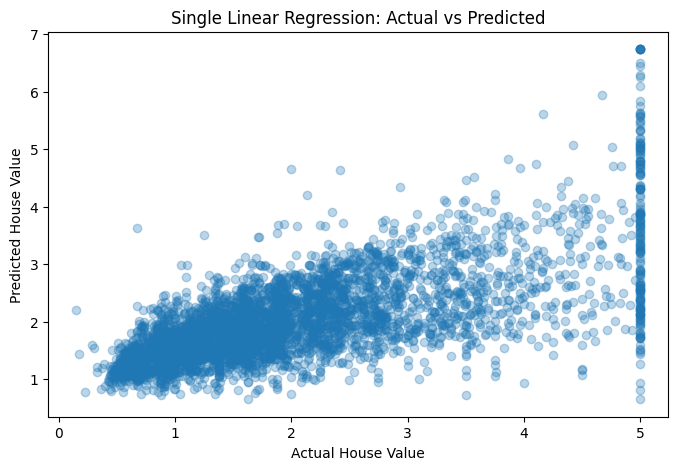

In [27]:

plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    single_predictions,
    alpha=0.3
)

plt.xlabel("Actual House Value")
plt.ylabel("Predicted House Value")
plt.title("Single Linear Regression: Actual vs Predicted")

plt.show()


In [28]:

multiple_model = LinearRegression()

multiple_model.fit(X_train, y_train)

print("Model Trained Successfully")
print("Intercept:", multiple_model.intercept_)


Model Trained Successfully
Intercept: -37.02327770606405


In [29]:

coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': multiple_model.coef_
})

print(coefficients)


      Feature  Coefficient
0      MedInc     0.448675
1    HouseAge     0.009724
2    AveRooms    -0.123323
3   AveBedrms     0.783145
4  Population    -0.000002
5    AveOccup    -0.003526
6    Latitude    -0.419792
7   Longitude    -0.433708


In [30]:

equation = f"MedHouseVal = {multiple_model.intercept_:.4f}"

for feature, coefficient in zip(X.columns, multiple_model.coef_):
    equation += f" + ({coefficient:.4f} * {feature})"

print("Multiple Linear Regression Equation:")
print(equation)


Multiple Linear Regression Equation:
MedHouseVal = -37.0233 + (0.4487 * MedInc) + (0.0097 * HouseAge) + (-0.1233 * AveRooms) + (0.7831 * AveBedrms) + (-0.0000 * Population) + (-0.0035 * AveOccup) + (-0.4198 * Latitude) + (-0.4337 * Longitude)


In [31]:

multiple_predictions = multiple_model.predict(X_test)

prediction_results = pd.DataFrame({
    'Actual House Value': y_test.values,
    'Predicted House Value': multiple_predictions
})

print(prediction_results.head(15))


    Actual House Value  Predicted House Value
0              0.47700               0.719123
1              0.45800               1.764017
2              5.00001               2.709659
3              2.18600               2.838926
4              2.78000               2.604657
5              1.58700               2.011754
6              1.98200               2.645500
7              1.57500               2.168755
8              3.40000               2.740746
9              4.46600               3.915615
10             1.23200               0.938962
11             2.53900               1.901222
12             2.15100               1.758712
13             2.20500               2.250160
14             2.19800               2.540870


In [32]:

multiple_mae = mean_absolute_error(
    y_test, multiple_predictions
)

multiple_mse = mean_squared_error(
    y_test, multiple_predictions
)

multiple_rmse = np.sqrt(multiple_mse)

multiple_r2 = r2_score(
    y_test, multiple_predictions
)

n = len(y_test)
p = X_test.shape[1]

multiple_adjusted_r2 = 1 - (
    (1 - multiple_r2) * (n - 1) / (n - p - 1)
)

print("MAE:", multiple_mae)
print("MSE:", multiple_mse)
print("RMSE:", multiple_rmse)
print("R2 Score:", multiple_r2)
print("Adjusted R2:", multiple_adjusted_r2)


MAE: 0.5332001304956561
MSE: 0.5558915986952438
RMSE: 0.745581383012776
R2 Score: 0.5757877060324512
Adjusted R2: 0.5749637928613562


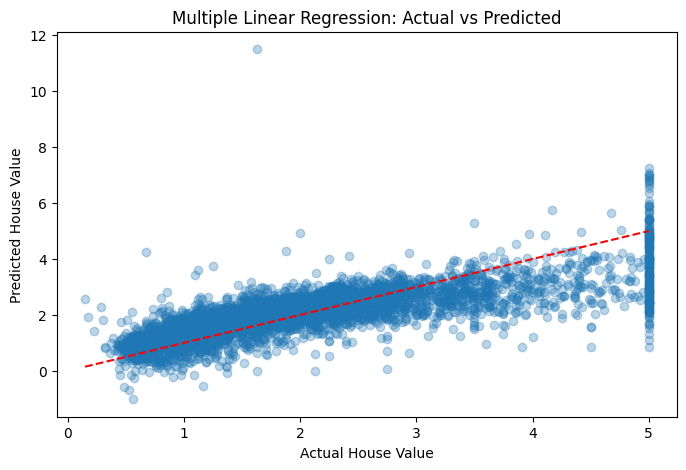

In [33]:

plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    multiple_predictions,
    alpha=0.3
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Actual House Value")
plt.ylabel("Predicted House Value")
plt.title("Multiple Linear Regression: Actual vs Predicted")

plt.show()


In [34]:

comparison = pd.DataFrame({
    'Metric': ['MAE', 'MSE', 'RMSE', 'R2 Score', 'Adjusted R2'],
    'Single Linear Regression': [
        single_mae,
        single_mse,
        single_rmse,
        single_r2,
        single_adjusted_r2
    ],
    'Multiple Linear Regression': [
        multiple_mae,
        multiple_mse,
        multiple_rmse,
        multiple_r2,
        multiple_adjusted_r2
    ]
})

print(comparison)


        Metric  Single Linear Regression  Multiple Linear Regression
0          MAE                  0.629909                    0.533200
1          MSE                  0.709116                    0.555892
2         RMSE                  0.842090                    0.745581
3     R2 Score                  0.458859                    0.575788
4  Adjusted R2                  0.458728                    0.574964


In [35]:

residuals = y_test - multiple_predictions

print("Residual Values:")
print(residuals.head(15))


Residual Values:
20046   -0.242123
3024    -1.306017
15663    2.290351
20484   -0.652926
9814     0.175343
13311   -0.424754
7113    -0.663500
7668    -0.593755
18246    0.659254
5723     0.550385
20069    0.293038
6835     0.637778
11351    0.392288
20267   -0.045160
7097    -0.342870
Name: MedHouseVal, dtype: float64


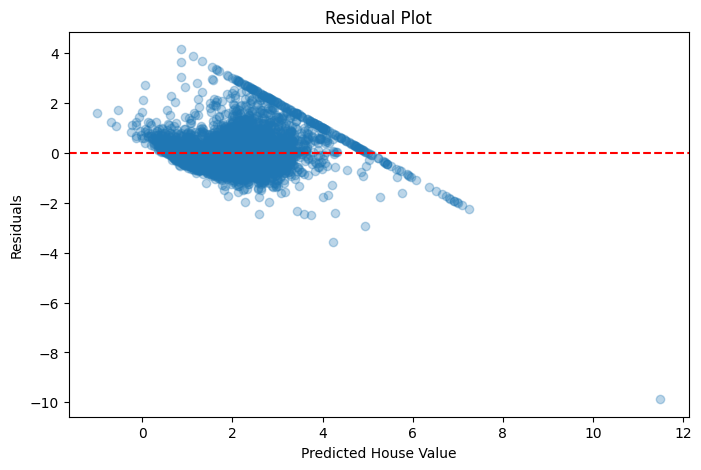

In [36]:

plt.figure(figsize=(8, 5))

plt.scatter(
    multiple_predictions,
    residuals,
    alpha=0.3
)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted House Value")
plt.ylabel("Residuals")
plt.title("Residual Plot")

plt.show()


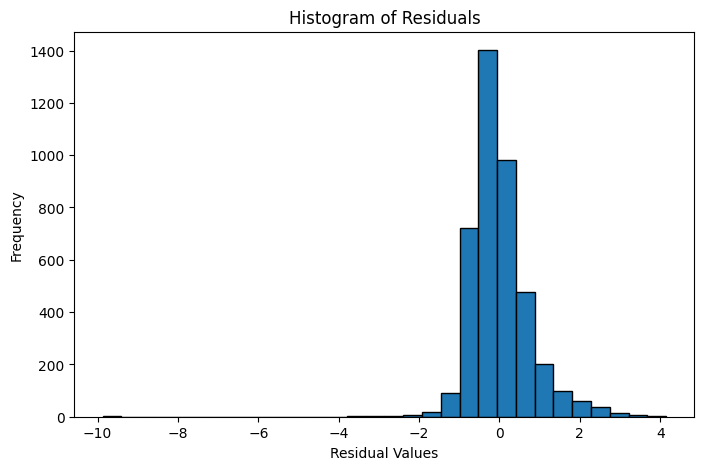

In [37]:

plt.figure(figsize=(8, 5))

plt.hist(
    residuals,
    bins=30,
    edgecolor='black'
)

plt.xlabel("Residual Values")
plt.ylabel("Frequency")
plt.title("Histogram of Residuals")

plt.show()


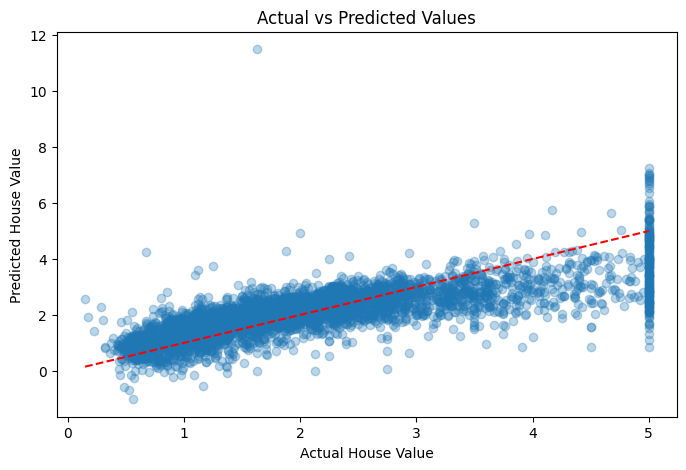

In [38]:

plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    multiple_predictions,
    alpha=0.3
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linestyle='--'
)

plt.xlabel("Actual House Value")
plt.ylabel("Predicted House Value")
plt.title("Actual vs Predicted Values")

plt.show()


In [39]:

vif_data = pd.DataFrame()

vif_data["Feature"] = X_train.columns

vif_data["VIF"] = [
    variance_inflation_factor(
        X_train.values, i
    )
    for i in range(X_train.shape[1])
]

print(vif_data.sort_values(by="VIF", ascending=False))


      Feature       VIF
6    Latitude  9.206134
7   Longitude  8.875984
2    AveRooms  7.917240
3   AveBedrms  6.609200
0      MedInc  2.539815
1    HouseAge  1.237337
4  Population  1.134824
5    AveOccup  1.009733


### Linear Regression Assumptions

1. **Linearity:** There should be a linear relationship between independent variables and the target variable.

2. **Independence of Errors:** The prediction errors should be independent of each other.

3. **Homoscedasticity:** The variance of residuals should remain approximately constant.

4. **Normality of Errors:** Residuals should be approximately normally distributed.

5. **No Severe Multicollinearity:** Independent variables should not have excessive correlation with each other.

These assumptions were examined using scatter plots, residual plots, residual histograms and VIF analysis. Some assumptions may require further investigation, especially because the dataset contains geographical observations.

In [40]:
new_house = X_train.median().to_frame().T

new_prediction = multiple_model.predict(new_house)[0]

print("New House Features:")
print(new_house)

print("\nPredicted Median House Value:", new_prediction)
print("Approximate Value in USD: $", new_prediction * 100000)

New House Features:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  3.5458      29.0  5.235874   1.049286      1167.0   2.81724     34.26   

   Longitude  
0    -118.51  

Predicted Median House Value: 2.030023600723055
Approximate Value in USD: $ 203002.3600723055


### Conclusion

In this project, California Housing data was used to build a house value prediction model using Linear Regression. Both Single Linear Regression and Multiple Linear Regression were implemented and evaluated.

The multiple linear regression model uses eight numerical features to predict the median house value. Its performance was compared with the single-feature model using MAE, MSE, RMSE, R² and Adjusted R².

The model demonstrates how multiple factors, such as median income, house age, number of rooms and location, can help estimate median house values. The final model can be used as a basic prediction tool, but its predictions should be treated as estimates rather than exact property prices.

### Limitations

1. The dataset represents median house values for districts, not individual houses.
2. The model assumes a linear relationship between input features and the target.
3. Some factors affecting house prices, such as property condition and nearby facilities, are not included.
4. Predictions may be less accurate for areas with unusual housing conditions.
5. The model is trained on historical data and may not reflect current market prices.bold text

### Decision Log

| Decision | Reason |
|---|---|
| Selected California Housing dataset | It contains numerical features and a continuous target |
| Used Median Income as the single feature | It has a strong relationship with median house value |
| Used an 80:20 train-test split | To evaluate the model on unseen data |
| Implemented Single Linear Regression | To create a baseline model |
| Implemented Multiple Linear Regression | To compare the effect of multiple features |
| Used MAE, MSE, RMSE and R² | To evaluate prediction performance |
| Checked correlation and VIF | To examine multicollinearity |
| Used residual plots | To inspect model errors and assumptions |

In [41]:
import os

os.makedirs("data", exist_ok=True)

df.to_csv("data/california_housing.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!
